# 11.0 — Scientific setup and data opportunity inventory

**Milestone 11 · Discovering the physics of NFL movement transfer.** Exploratory research — not a submission, not a dashboard.

**Question.** Which Combine drills and which NFL movement demands share a *measurable physical quantity*, for which positions, and for how many linked athletes?

**What this notebook builds (shared by every track):**
1. Drill inventory of EVERY tracked drill (names read from the warehouse, mapped to physical families by pattern — review the mapping).
2. NFL opportunity inventory from the persisted 09A episodes (no tracking rescan).
3. The shared feature foundation: drill-specific attempt features, transitions, segmenter agreement, athlete features, repeatability.
4. Declared NFL physical targets with exposure and game split-half reliability.
5. Cross-domain feasibility matrix: drill family × NFL demand × position → `SUPPORTED · LIMITED · UNSUPPORTED · UNKNOWN`. A shared generic column is never an overlap: the movement state must match (`m11.inventory.PHYSICAL_OVERLAP`, declared before any count was read).
6. The corrected Movement Gap definitions (engine 10.2): the forty cannot measure braking, change of direction or re-acceleration. The 10.1 outputs of 10C are kept as history.

**Prerequisites (same `RUN_MODE`).** 00 (athlete registry), 05A (play table), 06A (folds, optional), 09A–09C. **Reuse only:** nothing of the warehouse is rebuilt.

**Units.** athlete = sample size · attempt / episode / frame = dependent observations.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full' — smoke writes under _sample and its numbers are wiring checks only
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
DRILL_OVERRIDES = {}          # e.g. {'SOME_DRILL_NAME': 'backpedal_transition'} after reviewing section 2
COMPUTE_FEATURES = True       # False = reuse the saved feature foundation of this run mode

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import movement_gap as mg
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import inventory as inv
from nflbdb.research.advanced_movement.m11 import nfl_physics as nph
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import validation as v11

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
S = src.M11Sources(cfg, store, C, overrides=DRILL_OVERRIDES)
PROV = m11c.provenance('11.0', controls, C)
W = store.write_frame
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config hash `{C.hash()}`'))
display(store.describe())

**Run mode: `full`** (FULL) · config hash `adfe53ee38110026`

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Notebook-callable checks (synthetic fixtures — software verification only)

Units, sampling, speed bands, censoring, segmentation, geometry, linkage, grouped folds, training-only transforms, outcomes, resampling, checkpoints, artifact integrity. No project data is read; nothing here is a finding.

In [3]:
checks = v11.run_all(v11.ALL_CHECKS)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(checks)
v11.assert_all_passed(checks)

check,status,detail
str,str,str
"""physical_units_and_speed_bands""","""PASS""","""band time, band acceleration (yd/s²) exact on a ramp; first-crossing rule identical to movement_demands"""
"""sensor_sampling_irregular_clock""","""PASS""","""acceleration uses the recorded clock: exact enough on an irregular sampling grid"""
"""censoring""","""PASS""","""start / end censoring yields NaN with explicit flags; nothing is extrapolated"""
"""player_linkage""","""PASS""","""drill names map to physical families by pattern (+ overrides); twin pairs need both athletes linked"""
"""athlete_grouped_folds""","""PASS""","""athlete folds: Milestone 06 folds reused, others stratified; an athlete split across folds raises"""
"""training_only_transformations""","""PASS""","""scaling, imputation, dummies and family PCA use training athletes only"""
"""checkpoint_compatibility""","""PASS""","""immutable shards, config-hashed directories, verified sidecars, completion gate, tamper detection"""
"""saved_artifact_integrity""","""PASS""","""evidence schema, level rules without promotion, corrected Movement Gap classes"""
"""sprint_model_recovery""","""PASS""","""time-form and offset-free phase-plane sprint fits recover Vmax, τ, A0 = Vmax/τ"""


## 2 · Drill names and physical families

Drill identifiers are read from `combine_frame_kinematics`. Families come from name patterns (`m11.sources.DRILL_FAMILIES`). **Review `other`**: an unmapped drill is `UNKNOWN` in every feasibility cell until you add it to `DRILL_OVERRIDES` (cell 2) and re-run.

In [4]:
names = S.drill_names()
with pl.Config(tbl_rows=-1, tbl_width_chars=200):
    display(names)
W(names, 'm11_drill_mapping')
print('families present:', sorted(names['family'].unique().to_list()))

drill,drill_name,drill_type,n_attempts,n_athletes,n_frames,family
str,str,str,u32,u32,u32,str
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""BACK_PEDAL_AND_90_DEGREE_BREAK…","""SKILL_DRILLS_DB""",124,122,8422,"""backpedal_transition"""
"""BACK_PEDAL_AND_REACT""","""BACK_PEDAL_AND_REACT""","""SKILL_DRILLS_DL""",58,55,6057,"""backpedal_transition"""
"""BACK_PEDAL_AND_REACT""","""BACK_PEDAL_AND_REACT""","""SKILL_DRILLS_LB""",4,4,448,"""backpedal_transition"""
"""BACK_PEDAL_AND_TRANSITION_45_D…","""BACK_PEDAL_AND_TRANSITION_45_D…","""SKILL_DRILLS_DB""",241,122,21569,"""backpedal_transition"""
"""BLOCK_EXPLOSION""","""BLOCK_EXPLOSION""","""SKILL_DRILLS_TE""",40,39,2330,"""other"""
"""BODY_CONTROL_DRILL""","""BODY_CONTROL_DRILL""","""SKILL_DRILLS_DL""",113,111,6611,"""three_cone"""
"""BOX_DRILL""","""BOX_DRILL""","""SKILL_DRILLS_DB""",125,122,9439,"""other"""
"""CIRCUS_ROUTE_LEFT""","""CIRCUS_ROUTE_LEFT""","""SKILL_DRILLS_WR""",43,37,2551,"""other"""
"""COMEBACK_ROUTE_RIGHT""","""COMEBACK_ROUTE_RIGHT""","""SKILL_DRILLS_WR""",110,98,6647,"""other"""


families present: ['backpedal_transition', 'forty', 'gauntlet', 'other', 'pass_rush', 'short_shuttle', 'three_cone']


## 3 · Combine drill inventory

Per drill: athletes, attempts, positions, frames, recording duration, sampling (median Δt, share of irregular steps), coordinate / speed / acceleration / heading coverage, start censoring (first-frame speed ≥ 1 yd/s), end censoring (last-frame speed ≥ 80 % of the peak) and quality exclusions (`reject` tier).

family,drill,n_athletes,n_attempts,n_frames,duration_p50_s,duration_p95_s,dt_median_s,share_irregular_dt,coverage_xy,coverage_speed,coverage_accel,coverage_heading,peak_speed_p50,share_start_censored,share_end_censored,n_quality_excluded,n_usable_attempts,positions
str,str,i64,i64,i64,f32,f32,f32,f64,f64,f64,f64,f64,f32,f64,f64,i64,i64,str
"""forty""","""FORTY_YARD_DASH""",418,793,41500,5.0,5.8,0.1,0.0,1.0,1.0,0.999713,0.965867,10.603507,0.081967,1.0,0,793,"""DB:102, OL:95, WR:94, DL:93, TE:34"""
"""short_shuttle""","""SHORT_SHUTTLE""",170,223,11690,5.0,6.29,0.1,0.0,1.0,1.0,0.993538,0.843759,6.039517,0.170404,0.896861,0,223,"""OL:54, DL:38, WR:29, DB:28, TE:21"""
"""three_cone""","""BODY_CONTROL_DRILL""",111,113,6611,5.6,6.98,0.1,0.0,1.0,1.0,0.999047,0.95685,8.17908,0.265487,0.99115,0,113,"""DL:111"""
"""three_cone""","""OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT""",98,98,4412,4.3,5.115,0.1,0.0,1.0,1.0,0.987542,0.84703,7.980432,0.061224,0.989796,0,98,"""OL:98"""
"""three_cone""","""OL_PULL_DRILL_FOLD_BLOCK_RIGHT""",119,119,4706,3.7,4.77,0.1,0.0,1.0,1.0,0.994222,0.83188,7.165094,0.168067,0.983193,0,119,"""OL:119"""
"""three_cone""","""OL_PULL_DRILL_LONG_PULL_RIGHT""",93,93,4720,4.9,5.64,0.1,0.0,1.0,1.0,0.997483,0.917538,7.020389,0.096774,0.989247,0,93,"""OL:93"""
"""three_cone""","""THREE_CONE_DRILL""",160,203,15951,7.8,8.9,0.1,0.0,1.0,1.0,0.997936,0.86568,6.796884,0.300493,0.940887,0,203,"""OL:48, DL:45, WR:24, DB:24, TE:19"""
"""gauntlet""","""GAUNTLET_DRILL""",267,404,38228,9.15,11.1,0.1,0.0,1.0,1.0,0.981427,0.893473,8.741411,0.009901,0.938119,0,404,"""DB:119, WR:107, TE:41"""
"""backpedal_transition""","""BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL""",122,124,8422,6.6,8.285,0.1,0.0,1.0,1.0,0.997352,0.921426,8.153814,0.0,0.830645,0,124,"""DB:122"""


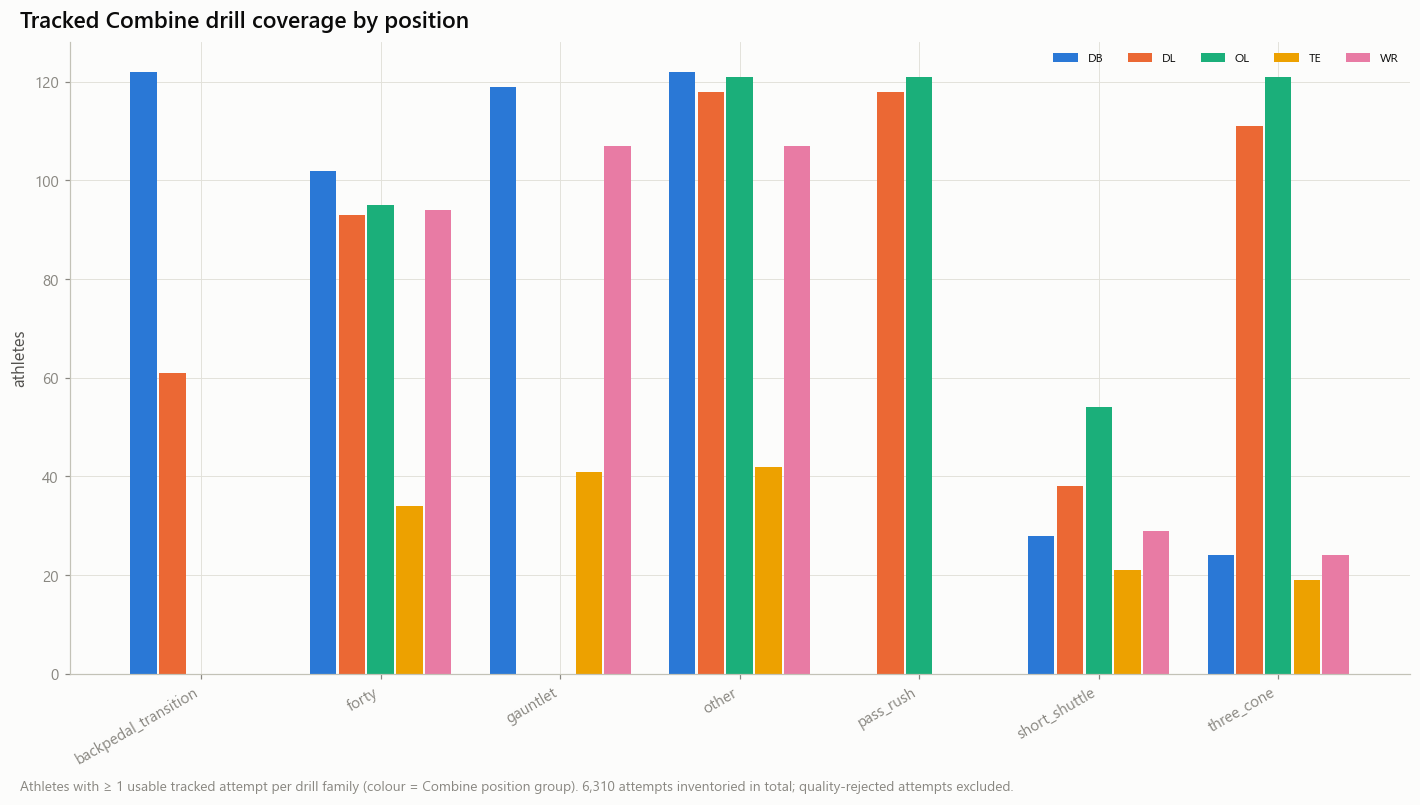

In [5]:
registry = S.athletes()
frames_all = S.combine_frames(usable_only=False)
summary = inv.attempt_summary(frames_all, registry)
q = S.inputs.trajectory_quality()
usable_ids = None if q is None else q.filter(pl.col('quality_tier') != 'reject').select((pl.col('event_id').cast(pl.String) + '|' + pl.col('nfl_id').cast(pl.String) + '|' + pl.col('attempt').cast(pl.String)).alias('s'))['s'].to_list()
drills = inv.drill_inventory(summary, usable_ids)
cover = inv.family_position_coverage(summary if usable_ids is None else summary.filter(pl.col('seq_id').is_in(usable_ids)))
W(summary, 'm11_attempt_summary', csv=False)
W(drills, 'm11_drill_inventory')
W(cover, 'm11_family_position_coverage')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=90):
    display(drills)
n_att = summary.height
store.show(fg.fig_grouped_bars(cover, 'family', 'position_group', 'n_athletes', 'Tracked Combine drill coverage by position',
                               f'Athletes with ≥ 1 usable tracked attempt per drill family (colour = Combine position group). {n_att:,} attempts inventoried in total; quality-rejected attempts excluded.',
                               'athletes'), 'AM11_00_01_drill_coverage_by_position', {'coverage': cover}, publication=True, source='combine_frame_kinematics', n=f'{n_att:,} attempts')

## 4 · NFL opportunity inventory

From the 09A episodes (edge episodes excluded) and the 05A play table: athletes, games, seasons, episodes per demand, speed-band opportunities, valid-heading turns, braking → re-acceleration pairs, label availability. Ball and opponent tracking are listed with their known status (08A): the warehouse tracking holds the project athletes only.

position_group,n_athletes,n_games,n_seasons,n_eligible_plays,first_season,last_season,n_brake_reaccel_pairs,n_pairs_with_turn,n_athletes_pairs
str,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""DB""",96,687,3,63914,2023,2025,7093,472,90
"""DL""",98,718,3,50363,2023,2025,3921,79,94
"""OL""",91,714,3,82806,2023,2025,590,1,74
"""TE""",33,496,3,8124,2023,2025,1371,74,30
"""WR""",83,753,3,36836,2023,2025,5021,376,82


label,share_episodes_labelled,n_levels
str,f64,i64
"""route_label""",0.273657,12
"""coverage_label""",0.374428,20
"""play_class""",1.0,3
"""side""",1.0,3
"""lined_up_position""",0.989249,16
"""down""",0.989249,5


item,status,note
str,str,str
"""ball tracking""","""UNKNOWN""","""not used by Milestones 05–10; …"
"""opponent tracking""","""UNSUPPORTED""","""08A: nearest defender not reco…"
"""vendor separation (FO01)""","""LIMITED""","""08B registry frozen_explorator…"
"""body orientation (vendor o)""","""UNSUPPORTED""","""dropped by the 05A/09A reader;…"


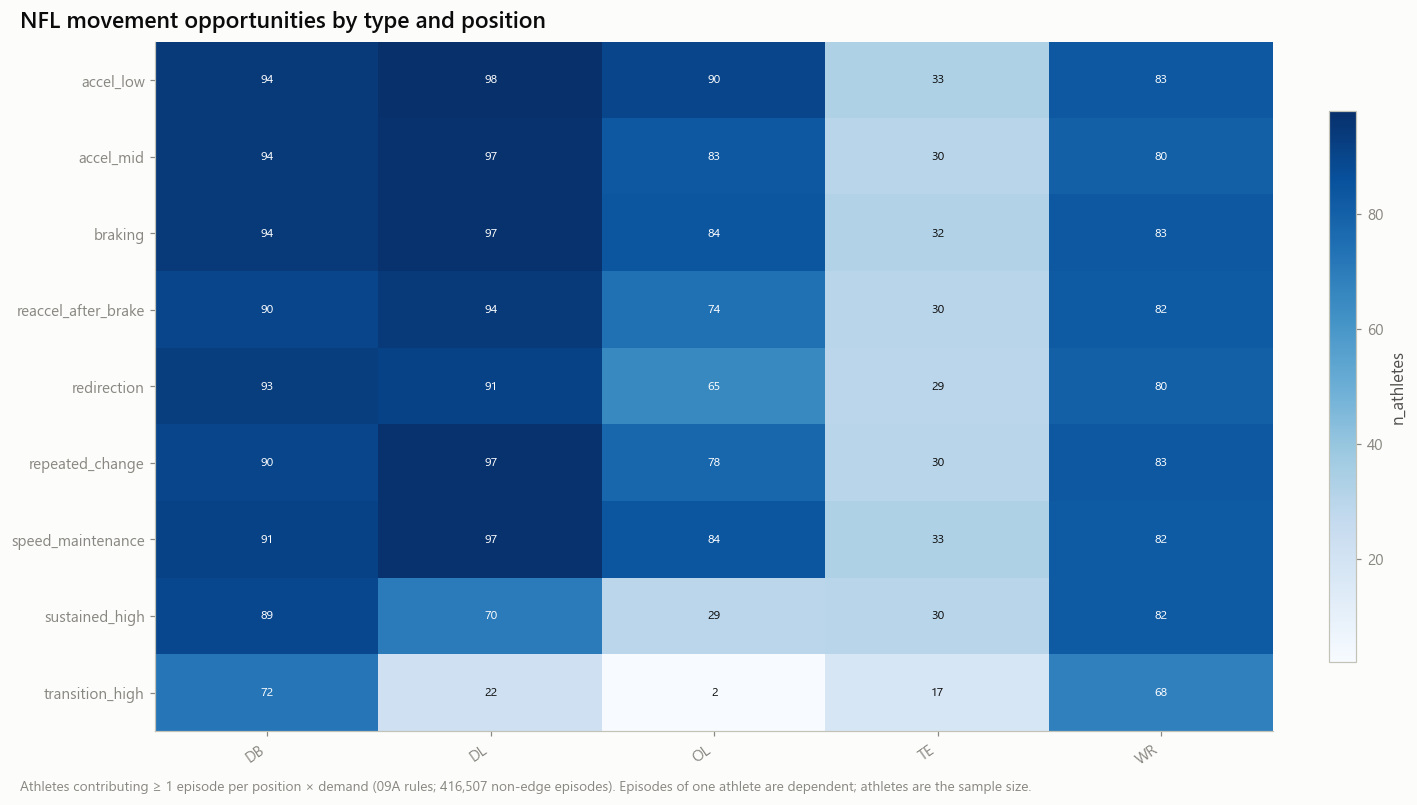

In [6]:
episodes = S.episodes()
plays = S.plays()
pairs = nph.brake_reaccel_pairs(episodes)
NI = inv.nfl_inventory(episodes, plays, pairs, C)
for k, v in NI.items():
    W(v, k)
W(pairs, 'm11_brake_reaccel_pairs', csv=False)
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    for k in ('m11_nfl_position_inventory', 'm11_nfl_label_availability', 'm11_nfl_context_availability'):
        display(NI[k])
n_ep = episodes.height
store.show(fg.fig_heatmap(NI['m11_nfl_demand_inventory'], 'demand_id', 'position_group', 'n_athletes', 'NFL movement opportunities by type and position',
                          f'Athletes contributing ≥ 1 episode per position × demand (09A rules; {n_ep:,} non-edge episodes). Episodes of one athlete are dependent; athletes are the sample size.'),
           'AM11_00_02_nfl_episode_coverage', {'demand_inventory': NI['m11_nfl_demand_inventory']}, publication=True, source='nfl_movement_demand_episodes', n=f'{n_ep:,} episodes')

## 5 · Officials and athlete folds

Official values only (forty, 10-yd split, weight, height; three-cone and short shuttle when the mart holds them). Folds: Milestone 06 folds are reused for the athletes they cover; the others are dealt by position × draft cohort. Every Combine attempt and every NFL season of an athlete follows its fold.

In [7]:
officials = S.officials()
folds = ev.assign_folds(officials, S.transfer_folds(), C.outer_folds, C.seed)
W(officials, 'm11_officials')
W(folds, 'm11_folds')
display(folds.group_by('fold', 'fold_source').len().sort('fold', 'fold_source'))
display(officials.select([pl.col(k).is_not_null().sum().alias(k) for k in ('forty', 'ten', 'weight', 'height', 'three_cone', 'short_shuttle')]))

16:51:40 | INFO    | nflbdb.research.advanced_movement.m11.sources | [m11.sources] official non-forty columns: {'three_cone': 'cmb_three_cone', 'short_shuttle': 'cmb_short_shuttle'}


fold,fold_source,len
i64,str,u32
0,"""m06""",59
0,"""m11""",45
1,"""m06""",55
1,"""m11""",45
2,"""m06""",57
2,"""m11""",45
3,"""m06""",59
3,"""m11""",44
4,"""m06""",57


forty,ten,weight,height,three_cone,short_shuttle
u32,u32,u32,u32,u32,u32
424,425,510,510,180,201


## 6 · Shared feature foundation (drill-specific families, transitions, repeatability)

`m11.combine_drills.attempt_tables` on every usable attempt: forty speed bands and sprint physics, transition metrics of shuttle / three-cone / long shuttle / transition drills (threshold segmenter, with changepoint and HMM agreement), pass-rush launch, gauntlet speed holding. Athlete value = mean of attempts. Repeatability = ICC(1) across attempts with an athlete-bootstrap interval.

**Run time.** One pass over the usable Combine frames (tens of thousands of attempts at most); the HMM is a few milliseconds per attempt.

In [8]:
if COMPUTE_FEATURES or not store.has('m11_attempt_features'):
    frames = frames_all if usable_ids is None else frames_all.filter(pl.col('seq_id').is_in(usable_ids))
    T = cd.attempt_tables(frames, C)
    for k, v in T.items():
        W(v, k, csv=False)
    ath = cd.athlete_features(T['m11_attempt_features'])
    rep = ev.repeatability_table(T['m11_attempt_features'], by=('feature',), n_boot=200 if not controls.smoke else 30, seed=C.seed)
    W(ath, 'm11_athlete_features', csv=False)
    W(rep, 'm11_repeatability')
else:
    T = {k: store.read_frame(k, '11.0') for k in ('m11_attempt_features', 'm11_combine_transitions', 'm11_segmenter_agreement', 'm11_attempt_index')}
    ath, rep = store.read_frame('m11_athlete_features', '11.0'), store.read_frame('m11_repeatability', '11.0')
print(f"{T['m11_attempt_features']['seq_id'].n_unique():,} attempts with features · {ath['nfl_id'].n_unique()} athletes · {T['m11_combine_transitions'].height:,} transitions")
with pl.Config(tbl_rows=40, tbl_width_chars=200):
    display(rep.sort('icc', descending=True, nulls_last=True))

6,310 attempts with features · 510 athletes · 1,633 transitions


feature,n_athletes,n_repeat,icc,icc_lo,icc_hi
str,i64,i64,f64,f64,f64
"""forty.band_4_6_censored""",418,375,NaN,NaN,NaN
"""forty.band_6_8_censored""",418,375,NaN,NaN,NaN
"""short_shuttle.curved_speed""",0,0,NaN,NaN,NaN
"""three_cone.brake_time_5_2_s""",11,0,NaN,NaN,NaN
"""forty.v_max_obs""",418,375,0.984984,0.982127,0.987825
"""forty.band_6_8_time_s""",418,375,0.939232,0.922662,0.954359
"""forty.band_8_10_censored""",418,375,0.939154,0.901093,0.970073
"""forty.speed_at_10yd""",408,320,0.935992,0.903272,0.95805
"""forty.band_8_10_time_s""",289,248,0.897573,0.870381,0.923157


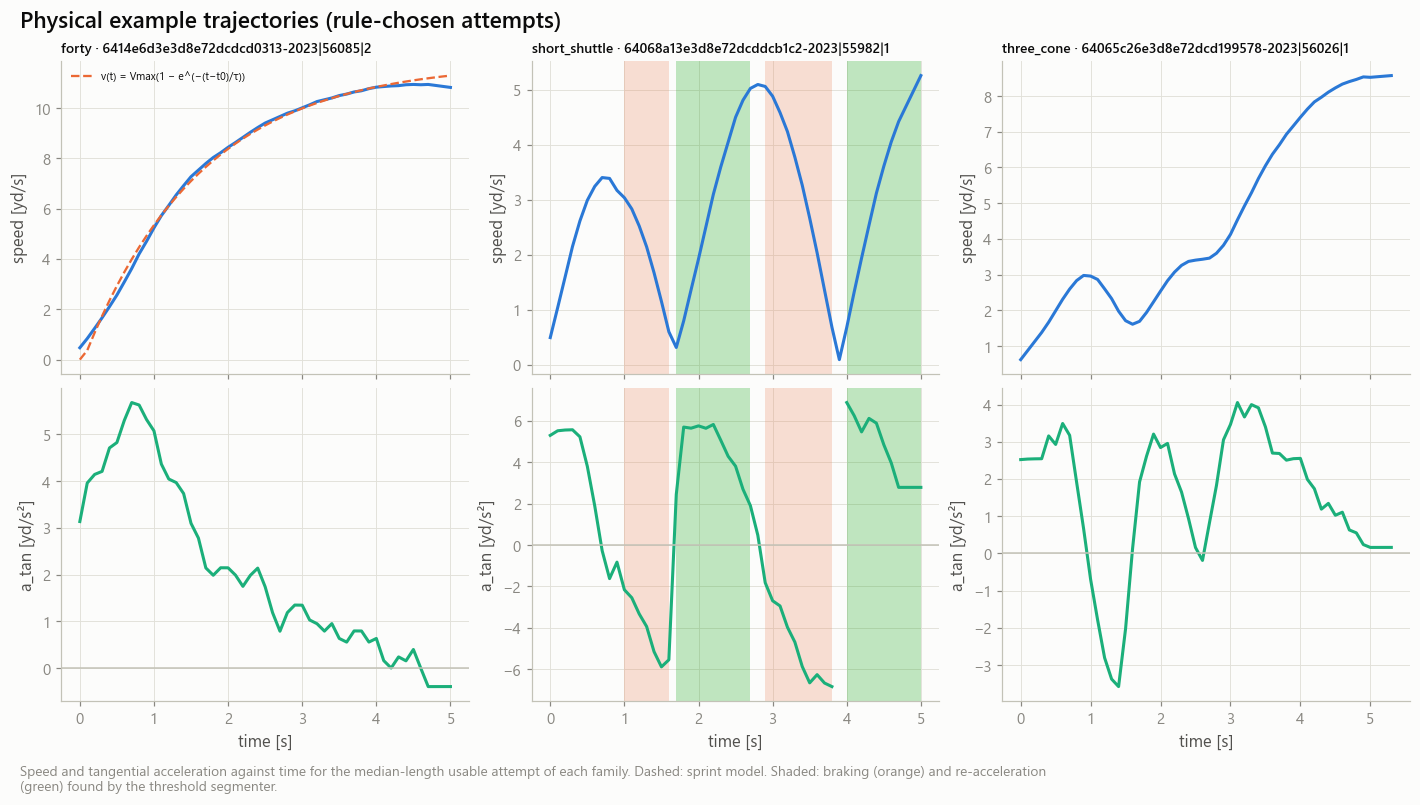

In [9]:
# physical example trajectories: the median-length forty and the median-length shuttle-type attempt (rule-chosen, no hand picking)
idx = T['m11_attempt_index']
examples = []
for fam in ('forty', 'short_shuttle', 'three_cone'):
    cand = idx.filter((pl.col('family') == fam) & (pl.col('n_frames') >= 20)).sort('n_frames', 'seq_id')
    if cand.height == 0:
        continue
    sid = cand['seq_id'][cand.height // 2]
    f = cd.longest_segment(frames_all.filter(pl.col('seq_id') == sid))
    t = f['t_s'].to_numpy() - f['t_s'][0]
    v, a = f['speed'].to_numpy(), f['a_tan'].to_numpy()
    tr = {'t': t, 'speed': v, 'a_tan': a, 'title': f'{fam} · {sid}'}
    if fam == 'forty':
        fit = cd.ph.fit_sprint_time(t, v, C.sprint_tau_grid, C.sprint_t0_grid, fit_offset=bool(v[0] < C.sprint_identifiable_v0))
        if fit['ok']:
            tr['fit'], tr['fit_label'] = cd.ph.sprint_speed(t, fit['vmax'], fit['tau'], fit['t0']), 'v(t) = Vmax(1 − e^(−(t−t0)/τ))'
    else:
        ts = cd.sg.transitions(t, v, a, f['vx'].to_numpy() if 'vx' in f.columns else None, f['vy'].to_numpy() if 'vy' in f.columns else None)
        tr['phases'] = [(t[d['i_brake']], t[d['i_brake_end'] - 1], 'braking') for d in ts] + [(t[d['i_accel']], t[d['i_accel_end'] - 1], 'reacceleration') for d in ts if d['i_accel'] >= 0]
    examples.append(tr)
store.show(fg.fig_traces(examples, 'Physical example trajectories (rule-chosen attempts)',
                         'Speed and tangential acceleration against time for the median-length usable attempt of each family. Dashed: sprint model. Shaded: braking (orange) and re-acceleration (green) found by the threshold segmenter.'),
           'AM11_00_03_example_trajectories', {}, publication=True, source='combine_frame_kinematics', n=f'{len(examples)} attempts')

## 7 · NFL physical targets

Declared targets (`m11.nfl_physics.TARGETS`): matched speed bands, acceleration from low speed, high-speed transition, observed top speed, braking, re-acceleration, redirection speed retention, Brake-to-Burst, pair Transition Cost Index and — for comparison only — the broad Milestone 05 primary. Athlete value = median over episodes (90th percentile for top speed); `supported` = at least `min_episodes_athlete` episodes. Reliability = game-parity split-half (Spearman–Brown).

In [10]:
targets = nph.athlete_targets(episodes, pairs, plays, C)
rel = nph.target_reliability(episodes, pairs, plays, C)
W(targets, 'm11_nfl_targets', csv=False)
W(rel, 'm11_nfl_target_reliability')
W(nph.target_dictionary(), 'm11_nfl_target_dictionary')
counts = targets.group_by('target_id').agg(pl.len().alias('n_athletes_any'), pl.col('supported').sum().alias('n_athletes_supported'), pl.col('n_episodes').median().alias('median_episodes'))
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(rel.join(counts, on='target_id', how='left'))

target_id,label,unit,n_athletes,r_half,reliability,n_episodes,n_athletes_any,n_athletes_supported,median_episodes
str,str,str,i64,f64,f64,i64,u32,u32,f64
"""nfl.band_2_4""","""acceleration through 2 → 4 yd/…","""yd/s²""",366,0.954374,0.976654,113101,394,370,159.5
"""nfl.band_4_6""","""acceleration through 4 → 6 yd/…","""yd/s²""",323,0.91789,0.957187,49812,377,280,38.0
"""nfl.band_6_8""","""acceleration through 6 → 8 yd/…","""yd/s²""",165,0.641662,0.781722,7960,223,137,18.0
"""nfl.accel_low_mean""","""mean acceleration from low spe…","""yd/s²""",378,0.966374,0.9829,228227,398,386,341.5
"""nfl.accel_low_peak05""","""peak 0.5-s speed gain from low…","""yd/s²""",378,0.976855,0.988292,228227,398,386,341.5
"""nfl.transition_high_mean""","""acceleration into high-speed r…","""yd/s²""",94,-0.06922,-0.148736,1197,181,44,4.0
"""nfl.vmax_p90""","""observed high-speed peak (90th…","""yd/s""",213,0.690161,0.816681,15659,300,175,21.0
"""nfl.brake_decel""","""mean deceleration while brakin…","""yd/s²""",354,0.726683,0.84171,67836,390,341,84.0
"""nfl.brake_peak05""","""peak 0.5-s deceleration""","""yd/s²""",354,0.757298,0.861889,67826,390,341,84.0


## 8 · Cross-domain feasibility matrix

State of every drill family × NFL demand × position, by declared rule: no overlap → `UNSUPPORTED` (never a zero effect), unmapped drill → `UNKNOWN`, overlap ≥ medium and ≥ `min_athletes_cell` linked athletes with enough episodes → `SUPPORTED`, ≥ `min_athletes_limited` → `LIMITED`. A linked athlete counts only where the Combine and NFL position groups agree.

family,demand_id,overlap_confidence,shared_quantity,n_linked_supported,n_combine_athletes,feasibility
str,str,str,str,i64,i64,str
"""backpedal_transition""","""accel_low""","""none""","""""",142,183,"""UNSUPPORTED"""
"""backpedal_transition""","""accel_mid""","""none""","""""",121,183,"""UNSUPPORTED"""
"""backpedal_transition""","""braking""","""medium""","""deceleration of the backpedal""",133,183,"""SUPPORTED"""
"""backpedal_transition""","""reaccel_after_brake""","""medium""","""forward acceleration after a backward / lateral phase""",116,183,"""SUPPORTED"""
"""backpedal_transition""","""redirection""","""medium""","""change of direction of motion""",108,183,"""SUPPORTED"""
"""backpedal_transition""","""repeated_change""","""none""","""""",116,183,"""UNSUPPORTED"""
"""backpedal_transition""","""speed_maintenance""","""none""","""""",116,183,"""UNSUPPORTED"""
"""backpedal_transition""","""sustained_high""","""none""","""""",88,183,"""UNSUPPORTED"""
"""backpedal_transition""","""transition_high""","""none""","""""",25,183,"""UNSUPPORTED"""


feasibility,len
str,u32
"""UNKNOWN""",45
"""UNSUPPORTED""",202
"""LIMITED""",43
"""SUPPORTED""",25


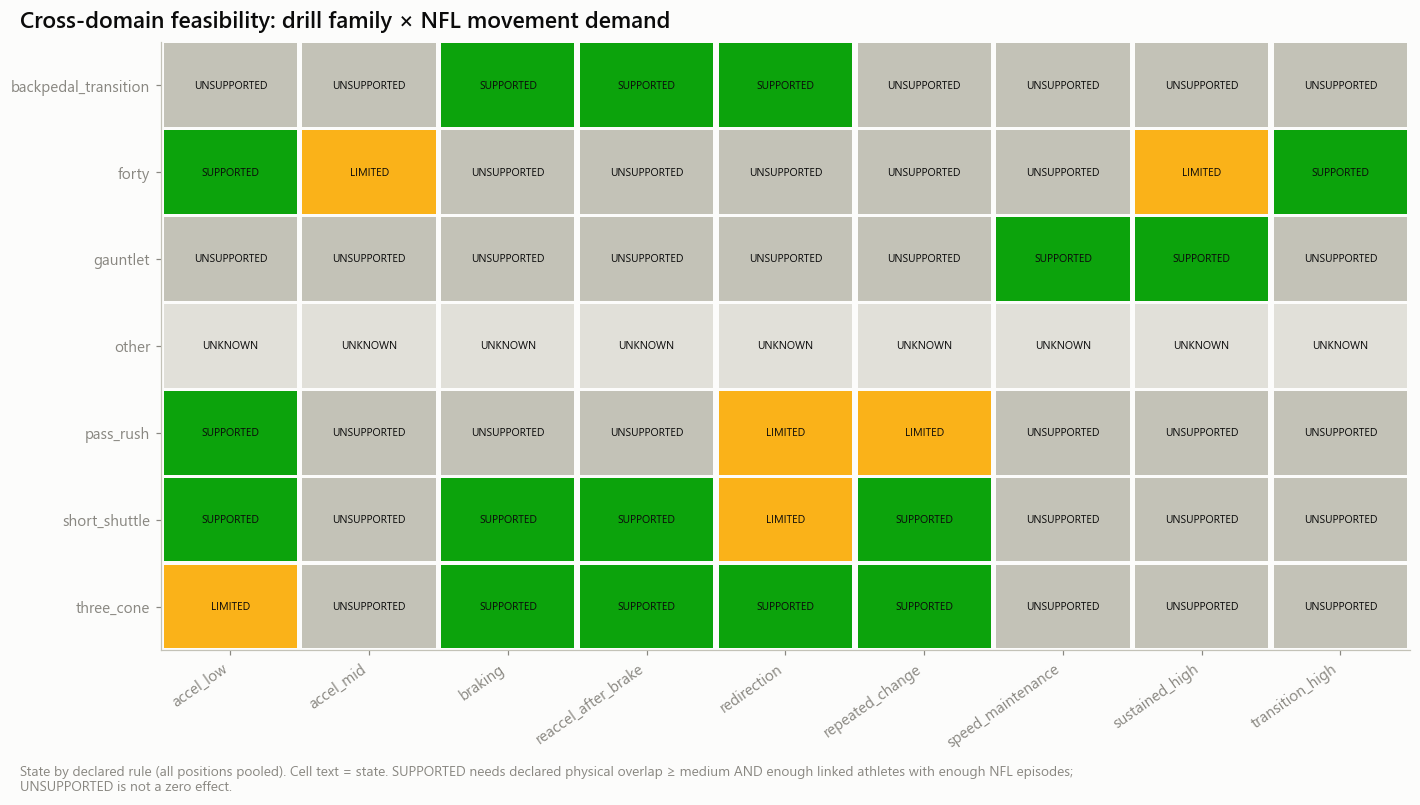

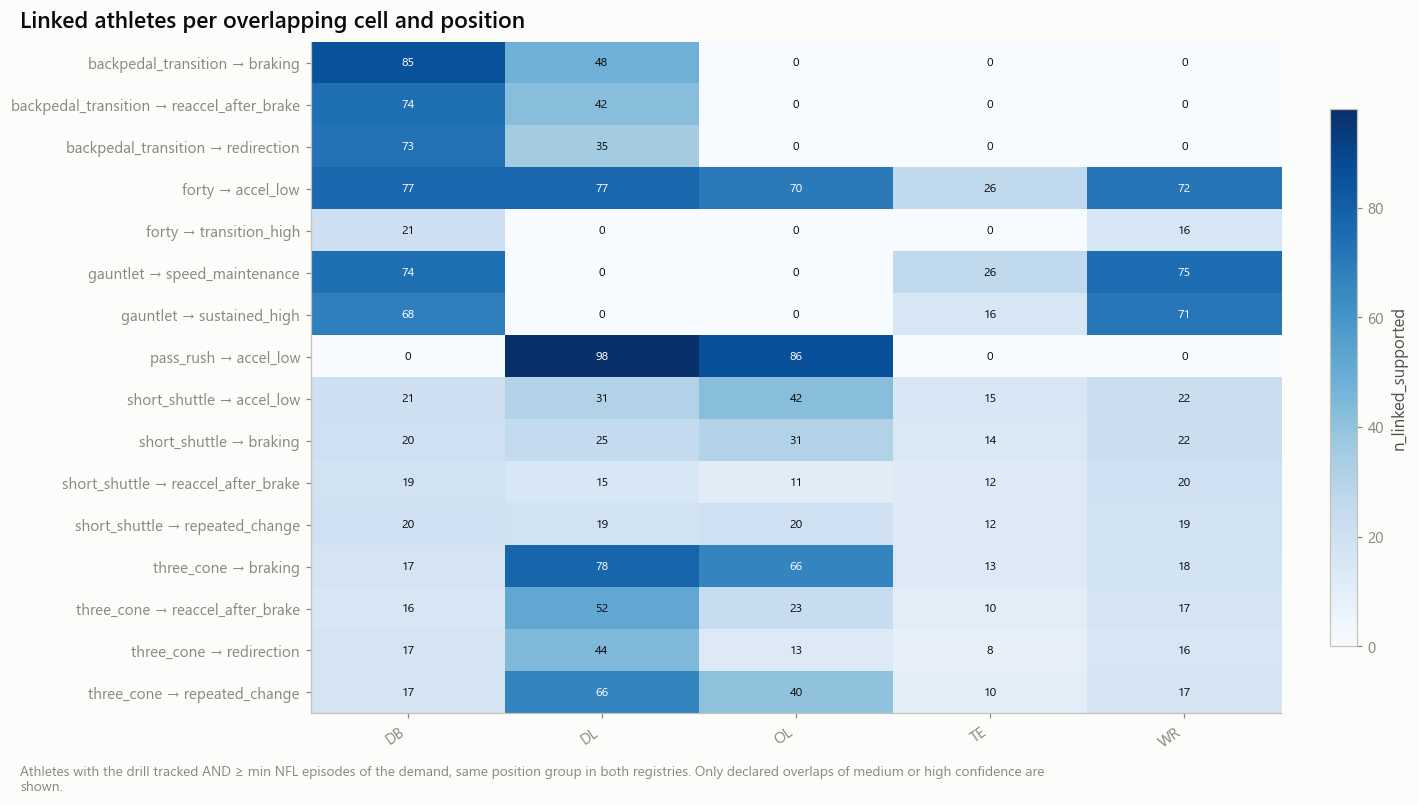

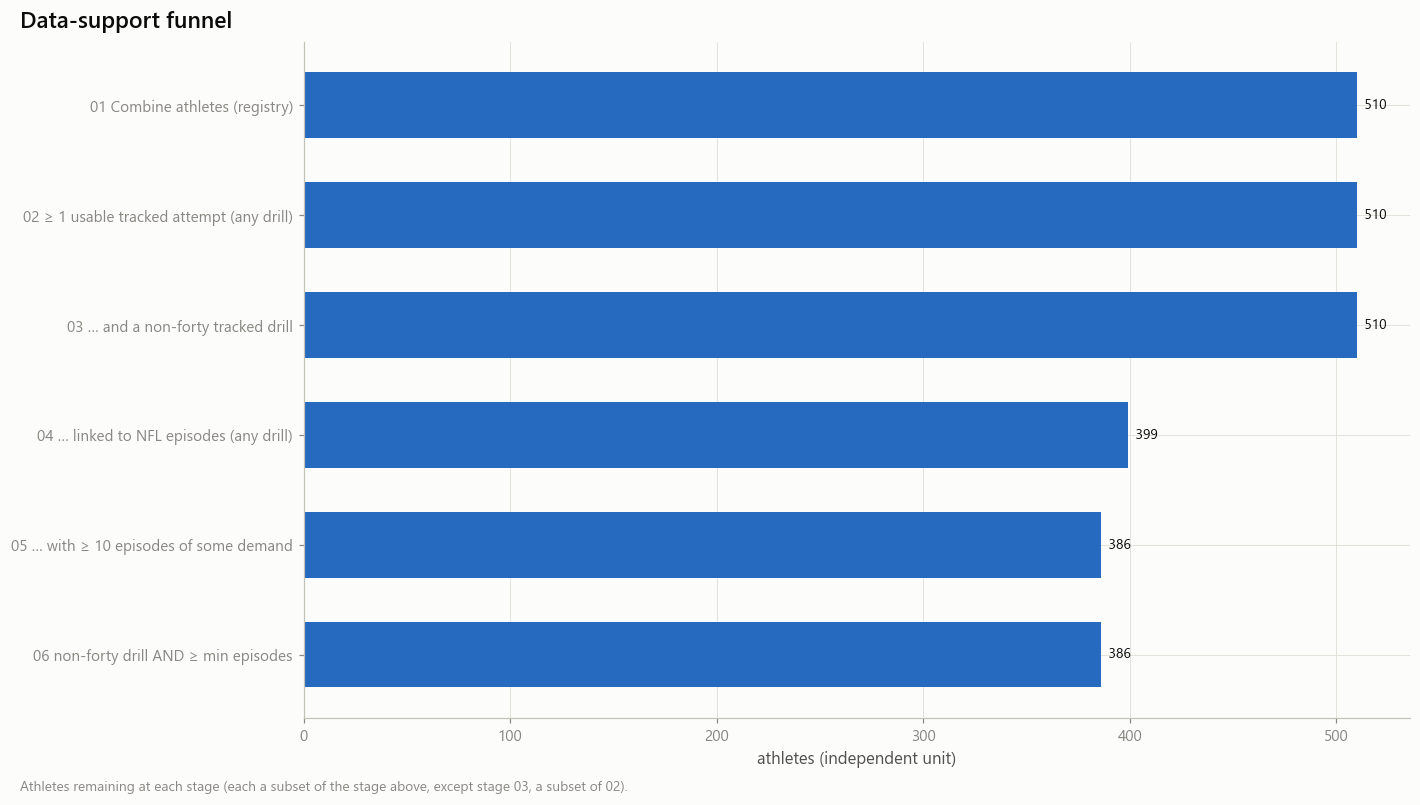

In [11]:
att_ath = T['m11_attempt_index'].select('nfl_id', 'family').unique().join(officials.select('nfl_id', 'position_group'), on='nfl_id', how='inner')
nfl_ath = episodes.group_by('nfl_id', 'position_group', 'demand_id').agg(pl.len().alias('n_episodes'))
fm = inv.feasibility_matrix(att_ath, nfl_ath, C)
pooled = inv.pooled_feasibility(fm, C)
funnel = inv.support_funnel(registry, att_ath, nfl_ath, C)
W(fm, 'm11_feasibility_matrix')
W(pooled, 'm11_feasibility_pooled')
W(funnel, 'm11_support_funnel')
with pl.Config(tbl_rows=-1, tbl_width_chars=220, fmt_str_lengths=60):
    display(pooled)
    display(fm.group_by('feasibility').len())
store.show(fg.fig_state_grid(pooled, 'family', 'demand_id', 'feasibility', fg.FEAS_COLORS, 'Cross-domain feasibility: drill family × NFL movement demand',
                             'State by declared rule (all positions pooled). Cell text = state. SUPPORTED needs declared physical overlap ≥ medium AND enough linked athletes with enough NFL episodes; UNSUPPORTED is not a zero effect.',
                             label='feasibility'), 'AM11_00_04_feasibility_heatmap', {'pooled': pooled}, publication=True, source='m11_feasibility_pooled')
store.show(fg.fig_heatmap(fm.filter(pl.col('overlap_confidence').is_in(['high', 'medium'])).with_columns((pl.col('family') + ' → ' + pl.col('demand_id')).alias('cell')),
                          'cell', 'position_group', 'n_linked_supported', 'Linked athletes per overlapping cell and position',
                          'Athletes with the drill tracked AND ≥ min NFL episodes of the demand, same position group in both registries. Only declared overlaps of medium or high confidence are shown.'),
           'AM11_00_05_linked_athletes_by_position', {}, publication=False, source='m11_feasibility_matrix')
store.show(fg.fig_funnel(funnel, 'Data-support funnel', 'Athletes remaining at each stage (each a subset of the stage above, except stage 03, a subset of 02).'),
           'AM11_00_06_support_funnel', {'funnel': funnel}, publication=True, source='m11_support_funnel')

## 9 · Cross-domain measurement registry and the corrected Movement Gap (10.2)

**Correction.** The 09A registry stores a missing analogue as the text `none`; engine 10.1 read that text as a shared dimension, so braking, re-acceleration, redirection, speed maintenance and repeated changes were classed *unavailable (data limitation)*. Engine 10.2 classes them *not directly measured by the forty* — structurally, because the timed forty contains no braking, no turn and no re-acceleration. The executed 10C outputs are left untouched as history; the corrected definitions and matrix are written here as new versioned artifacts.

quantity,unit,combine_definition,nfl_definition,comparability,state
str,str,str,str,str,str
"""band_accel_2_4 / 4_6 / 6_8""","""yd/s²""","""forty: first crossings of lo and hi in the recorded trace""","""accelerating episode: same first-crossing rule""","""same rule, 10 Hz both sides; Combine passes the band once from rest, NFL from any start in…","""SUPPORTED"""
"""band_accel_8_10""","""yd/s²""","""forty: same rule (often censored: recordings end near the peak)""","""envelope at 9 yd/s (episodes hold no 8→10 band)""","""different estimator on the NFL side (envelope) — LIMITED""","""LIMITED"""
"""top speed""","""yd/s""","""forty: largest tracked speed (may be censored)""","""sustained_high: 90th percentile of episode peaks""","""game speed is rarely maximal""","""LIMITED"""
"""sprint A0 / Vmax ↔ envelope A0 / V0""","""yd/s² · yd/s""","""phase-plane fit a = A0 − (A0/V0) v on the rising forty""","""linear fit to the per-speed-bin 95th percentile of game a_tan""","""same functional form; one maximal effort vs an observed upper tail""","""SUPPORTED"""
"""deceleration""","""yd/s²""","""shuttle / cone: mean −a_tan over the braking run (a_tan ≤ −1)""","""braking episode: −(speed change / duration)""","""Combine: run-mean of frames; NFL: episode mean — same threshold, close definitions""","""SUPPORTED"""
"""Brake-to-Burst latency""","""s""","""braking end → first a_tan ≥ 1.5""","""braking end → start of the following accelerating run (a_tan ≥ 1)""","""burst threshold differs (1.5 vs 1.0 yd/s²) — declared, kept""","""LIMITED"""
"""Transition Cost Index""","""fraction""","""(v_entry − v 0.5 s after the speed minimum) / v_entry""","""(v_entry − v 0.5 s into the re-acceleration) / v_entry""","""anchor differs (minimum vs re-acceleration start, ≤ 1 s apart)""","""LIMITED"""
"""turn angle""","""deg""","""angle between mean velocity before / after (valid through a stop)""","""integrated yaw of a redirection episode (≥ 3 yd/s, valid heading)""","""Combine reversals pass through a stop; NFL turns are at speed""","""LIMITED"""
"""lateral acceleration""","""yd/s²""","""(vx·ay − vy·ax)/|v| above 1 yd/s""","""not persisted in the 09A episodes""","""Combine only""","""UNSUPPORTED"""


demand_id,label,registry_text_analogue,forty_analogue_v2,forty_can_measure,class_rule_v2,class_v1_bug,engine_version
str,str,str,str,bool,str,str,str
"""accel_low""","""acceleration from low speed""","""acc_2_4, acc_4_6""","""acc_2_4, acc_4_6""",true,"""direct / partial by start state""","""""","""10.2"""
"""accel_mid""","""acceleration from intermediate speed""","""acc_4_6, acc_6_8""","""acc_4_6, acc_6_8""",true,"""direct / partial by start state""","""""","""10.2"""
"""transition_high""","""transition into high-speed running""","""acc_6_8""","""acc_6_8""",true,"""direct / partial by start state""","""""","""10.2"""
"""sustained_high""","""sustained high-speed running""","""top_speed""","""top_speed""",true,"""direct / partial by start state""","""""","""10.2"""
"""speed_maintenance""","""speed maintenance""","""none""","""none""",false,"""not_measured (structural: the timed forty contains no such phase)""","""10.1 read the placeholder text 'none' as a dimension → 'unavailable (data limitation)'""","""10.2"""
"""braking""","""braking and deceleration""","""none""","""none""",false,"""not_measured (structural: the timed forty contains no such phase)""","""10.1 read the placeholder text 'none' as a dimension → 'unavailable (data limitation)'""","""10.2"""
"""reaccel_after_brake""","""acceleration following deceleration""","""none""","""none""",false,"""not_measured (structural: the timed forty contains no such phase)""","""10.1 read the placeholder text 'none' as a dimension → 'unavailable (data limitation)'""","""10.2"""
"""redirection""","""directional redirection""","""none""","""none""",false,"""not_measured (structural: the timed forty contains no such phase)""","""10.1 read the placeholder text 'none' as a dimension → 'unavailable (data limitation)'""","""10.2"""
"""repeated_change""","""repeated speed-change sequence""","""none""","""none""",false,"""not_measured (structural: the timed forty contains no such phase)""","""10.1 read the placeholder text 'none' as a dimension → 'unavailable (data limitation)'""","""10.2"""


demand_id,DB,DL,OL,TE,WR
str,str,str,str,str,str
"""accel_low""","""direct""","""direct""","""direct""","""direct""","""direct"""
"""accel_mid""","""partial""","""partial""","""partial""","""partial""","""partial"""
"""transition_high""","""direct""","""unavailable""","""unavailable""","""unavailable""","""direct"""
"""sustained_high""","""partial""","""partial""","""partial""","""partial""","""partial"""
"""speed_maintenance""","""not_measured""","""not_measured""","""not_measured""","""not_measured""","""not_measured"""
"""braking""","""not_measured""","""not_measured""","""not_measured""","""not_measured""","""not_measured"""
"""reaccel_after_brake""","""not_measured""","""not_measured""","""not_measured""","""not_measured""","""not_measured"""
"""redirection""","""not_measured""","""not_measured""","""not_measured""","""not_measured""","""not_measured"""
"""repeated_change""","""not_measured""","""not_measured""","""not_measured""","""not_measured""","""not_measured"""


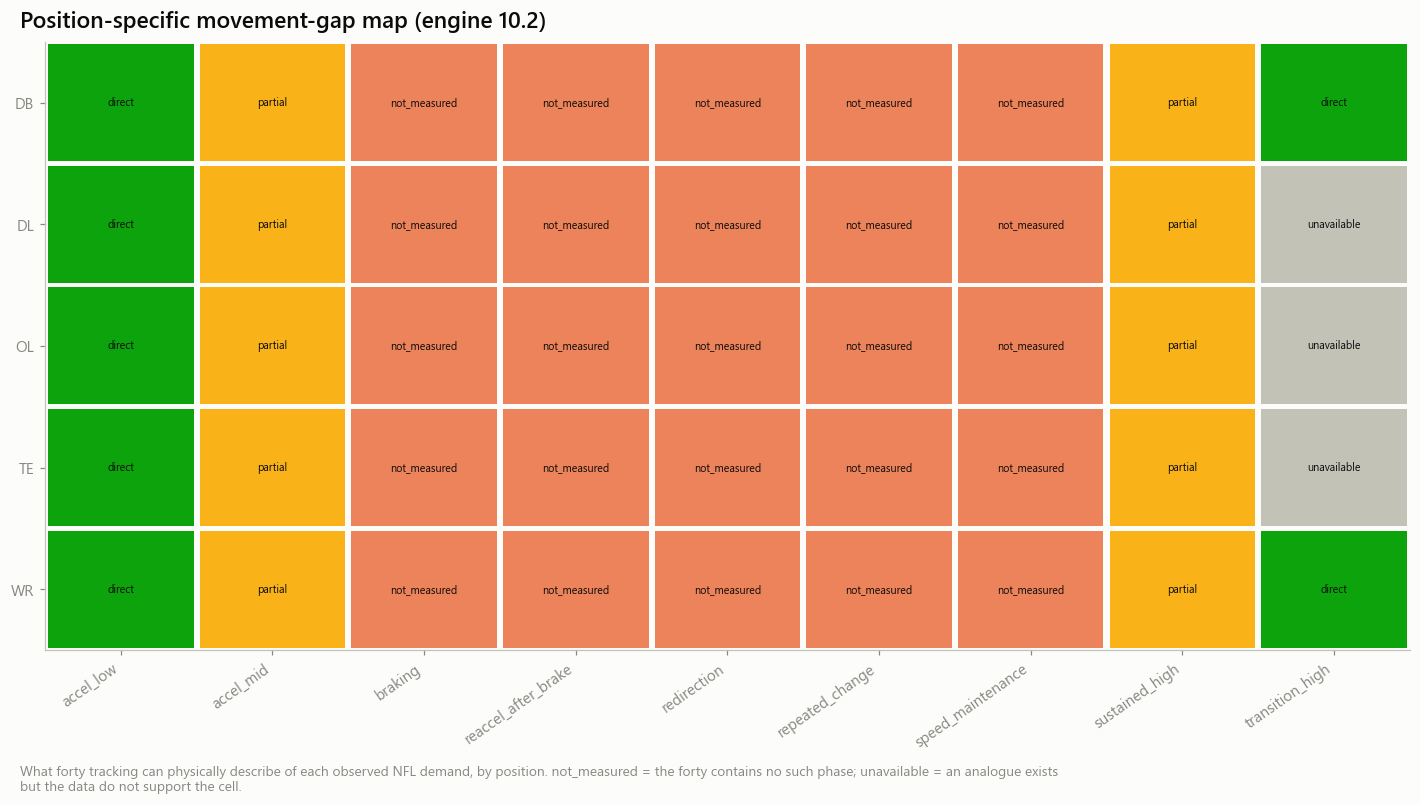

In [12]:
mreg = inv.measurement_registry()
REG = S.demand_registry()
gap_reg = inv.movement_gap_registry_v2(REG)
W(mreg, 'm11_measurement_registry')
W(gap_reg, 'm11_movement_gap_registry_v2')
freq = store.intelligence.require_named('nfl_movement_demand_frequency', src.NB['09A'])
msum = store.intelligence.require_named('movement_matching_summary', src.NB['09B'])
G = pl.DataFrame(mg.gap_matrix(REG.to_dicts(), freq.filter(pl.col('position_group') != 'ALL').to_dicts(), msum.to_dicts()))
W(G, 'm11_movement_gap_matrix_v2')
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=90):
    display(mreg)
    display(gap_reg)
    display(G.pivot(on='position_group', index='demand_id', values='coverage_class'))
store.show(fg.fig_state_grid(G, 'position_group', 'demand_id', 'coverage_class',
                             {mg.DIRECT: fg.STATUS['good'], mg.PARTIAL: fg.STATUS['warning'], mg.NOT_MEASURED: fg.STATUS['serious'], mg.UNAVAILABLE: fg.INK['axis']},
                             'Position-specific movement-gap map (engine 10.2)', 'What forty tracking can physically describe of each observed NFL demand, by position. not_measured = the forty contains no such phase; unavailable = an analogue exists but the data do not support the cell.',
                             label='coverage_class'), 'AM11_00_07_movement_gap_map_v2', {'gap_matrix_v2': G}, publication=True, source='09A frequency + registry, 09B summary')

## 10 · Research configuration manifest and conclusion

The sentences below are assembled from the tables of this run.

## 11.0 — conclusion (executed_exploratory; run mode full; generated 2026-10-14T16:57:01Z)

### Research question
Which Combine drills and NFL movement demands share a measurable physical quantity, and for how many linked athletes?

### Hypothesis
Not a hypothesis test: an inventory.

### Sample
510 Combine athletes, 6,310 tracked attempts over 62 drill identifiers; 399 NFL athletes, 416,507 episodes.

### Main evidence
- other: 510 athlete-position entries with a usable attempt
- forty: 418 athlete-position entries with a usable attempt
- three_cone: 299 athlete-position entries with a usable attempt
- gauntlet: 267 athlete-position entries with a usable attempt
- pass_rush: 239 athlete-position entries with a usable attempt
- backpedal_transition: 183 athlete-position entries with a usable attempt
- short_shuttle: 170 athlete-position entries with a usable attempt
- SUPPORTED family × demand cells: backpedal_transition → braking, backpedal_transition → reaccel_after_brake, backpedal_transition → redirection, forty → accel_low, forty → transition_high, gauntlet → speed_maintenance, gauntlet → sustained_high, pass_rush → accel_low, short_shuttle → accel_low, short_shuttle → braking, short_shuttle → reaccel_after_brake, short_shuttle → repeated_change, three_cone → braking, three_cone → reaccel_after_brake, three_cone → redirection, three_cone → repeated_change
- LIMITED cells: 6
- Funnel: 510 · 510 · 510 · 399 · 386 · 386 athletes
- Movement Gap 10.2: 5 of 9 demands are not measurable by the forty

### Alternative explanations
- Non-forty drill participation is selected (position, invitation, injury): counts describe who was tracked, not prospects in general.

### Practical scouting relevance
Defines which Combine → NFL comparisons are physically meaningful and how many athletes each can use; nothing here is a performance claim.

### Limitations
- Overlap confidence is a declared judgement, not a measurement.
- Drill-name mapping is pattern-based: check family other.

### Next experiment
- Run 11B (speed states and envelopes) and 11C (transitions) on the SUPPORTED cells.


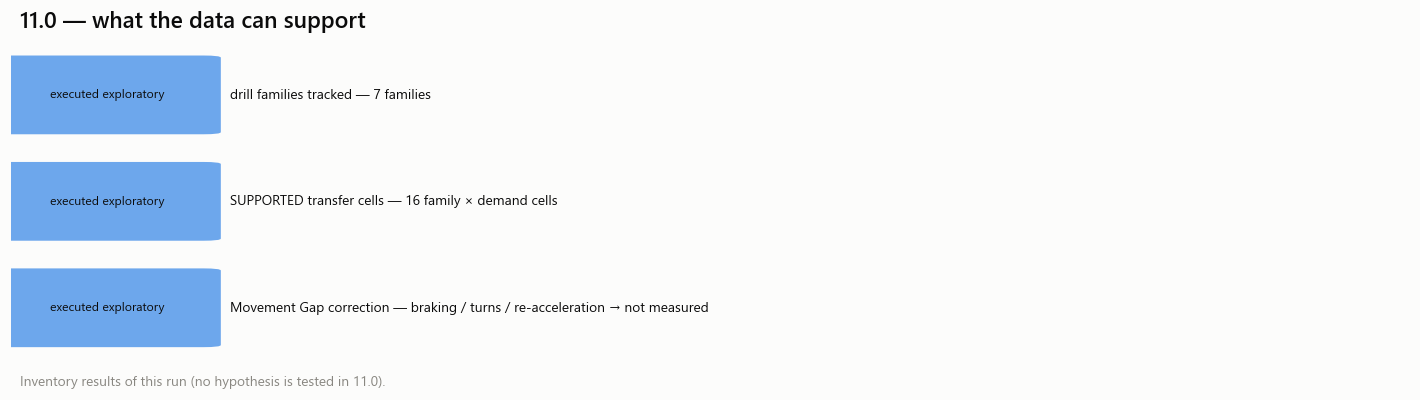

Send back: the checks table, the drill mapping (section 2), the drill inventory, the pooled feasibility table, the funnel, and the conclusion above.
Next: 11b_speed_state_transfer_and_envelopes.ipynb


In [13]:
manifest = inv.config_manifest(C, names, DRILL_OVERRIDES, m11c.study_table())
if controls.save_tables:
    store.write_json('m11_research_config', {**manifest, 'provenance': PROV})
fam_n = cover.group_by('family').agg(pl.col('n_athletes').sum()).sort('n_athletes', descending=True)
sup = pooled.filter(pl.col('feasibility') == m11c.SUPPORTED)
lim = pooled.filter(pl.col('feasibility') == m11c.LIMITED)
facts = {'status': m11c.EXECUTED_EXPLORATORY, 'run_mode': controls.run_mode,
         'sample': f"{summary['nfl_id'].n_unique()} Combine athletes, {summary.height:,} tracked attempts over {names.height} drill identifiers; {episodes['nfl_id'].n_unique()} NFL athletes, {episodes.height:,} episodes.",
         'evidence': [f"{r['family']}: {r['n_athletes']} athlete-position entries with a usable attempt" for r in fam_n.iter_rows(named=True)]
                     + [f"SUPPORTED family × demand cells: {', '.join(a + ' → ' + b for a, b in sup.select('family', 'demand_id').rows()) or 'none'}",
                        f"LIMITED cells: {lim.height}", f"Funnel: {' · '.join(str(n) for n in funnel['n_athletes'].to_list())} athletes",
                        f"Movement Gap 10.2: {int((gap_reg['forty_can_measure'] == False).sum())} of {gap_reg.height} demands are not measurable by the forty"],
         'alternatives': ['Non-forty drill participation is selected (position, invitation, injury): counts describe who was tracked, not prospects in general.'],
         'relevance': 'Defines which Combine → NFL comparisons are physically meaningful and how many athletes each can use; nothing here is a performance claim.',
         'limitations': ['Overlap confidence is a declared judgement, not a measurement.', 'Drill-name mapping is pattern-based: check family other.'],
         'next': ['Run 11B (speed states and envelopes) and 11C (transitions) on the SUPPORTED cells.']}
md_ = rp.conclusion_markdown('11.0', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11.0', md_)
rp.run_manifest(store, '11.0', PROV, ['m11_drill_inventory', 'm11_feasibility_matrix', 'm11_athlete_features', 'm11_nfl_targets', 'm11_folds', 'm11_movement_gap_registry_v2'], m11c.EXECUTED_EXPLORATORY)
conclusion_rows = pl.DataFrame([{'item': 'drill families tracked', 'evidence': f'{fam_n.height} families', 'status': 'executed_exploratory'},
                                {'item': 'SUPPORTED transfer cells', 'evidence': f'{sup.height} family × demand cells', 'status': 'executed_exploratory'},
                                {'item': 'Movement Gap correction', 'evidence': 'braking / turns / re-acceleration → not measured', 'status': 'completed_statistical_comparison' if False else 'executed_exploratory'}])
store.show(fg.fig_conclusion(conclusion_rows, '11.0 — what the data can support', 'Inventory results of this run (no hypothesis is tested in 11.0).'), 'AM11_00_08_conclusion', {}, publication=True, source='this notebook')
print('Send back: the checks table, the drill mapping (section 2), the drill inventory, the pooled feasibility table, the funnel, and the conclusion above.')
print('Next: 11b_speed_state_transfer_and_envelopes.ipynb')